# Nursing Homes Operations in Ireland

## 1. Project Overview

This module focuses on nursing homes in Ireland and their role in providing long-term residential care for older people.

After exploring population growth, functional limitations and Home Support services in the previous modules, I now want to understand the residential side of long-term care.

The main goal is to investigate how nursing home capacity is distributed across Ireland and how it has changed over time.

## 2. Main Research Question

**Is nursing home capacity in Ireland keeping pace with the growing older population?**

To explore this question, I will focus on the number of registered nursing homes, their available capacity and the historical development of long-term care beds.

I will also consider the demographic findings from the first module to provide context for the analysis.

## 3. Data Sources

For this module, I selected two official data sources:

**HIQA — Register of Nursing Homes**

This dataset contains information about registered nursing homes in Ireland, including facility names, locations and maximum occupancy.

It will be used to explore the distribution of registered nursing homes and their capacity.

Source: [HIQA — Nursing Homes](https://www.hiqa.ie/areas-we-work/nursing-homes)

**Department of Health — JQ17: Long-term Care Nursing Beds**

This dataset provides historical information about long-term care nursing beds in Ireland, covering the period from 1987 to 2025.

It will be used to understand how the national number of beds has changed over time.

Source: [Department of Health — JQ17 CSV](https://assets.gov.ie/static/documents/7e1ab8df/JQ17_-_Long-term_care_nursing_beds.csv)

## 4. Initial Analysis Plan

I will begin by exploring the structure and quality of both datasets before deciding which indicators to calculate.

The initial analysis will focus on:

- Number of registered nursing homes.
- Registered capacity across facilities.
- Distribution of nursing homes by county or region, depending on the available information.
- Historical changes in the number of long-term care beds.
- Comparison with the growth of the older population.

## 5. Scope and Limitations

The two datasets provide different types of information.

The HIQA register contains facility-level information, while the JQ17 dataset provides historical national figures.

Therefore, I will first analyse them separately and only combine information if the definitions, periods and level of detail are compatible.

Registered capacity should not automatically be interpreted as the number of occupied beds. Similarly, the number of beds does not represent the total number of people receiving long-term care.

These differences will be considered when interpreting the results.


In [1]:
import pdfplumber
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_nursing_beds = pd.read_csv('../data/raw/JQ17_-_Long-term_care_nursing_beds.csv')

df_nursing_beds.head()

,STATISTIC,Statistic Label,YEAR,Year,BEDTYPE,Bed type,UNIT,VALUE,FLAG,Flag
0,LTCBEDS,Beds in residential long-term care facilities,1987,1987,NURSING,Long-term care nursing bed,Number,9400,NaN,NaN
1,LTCBEDS,Beds in residential long-term care facilities,1988,1988,NURSING,Long-term care nursing bed,Number,9450,NaN,NaN
2,LTCBEDS,Beds in residential long-term care facilities,1989,1989,NURSING,Long-term care nursing bed,Number,11443,NaN,NaN
3,LTCBEDS,Beds in residential long-term care facilities,1990,1990,NURSING,Long-term care nursing bed,Number,11195,NaN,NaN
4,LTCBEDS,Beds in residential long-term care facilities,1991,1991,NURSING,Long-term care nursing bed,Number,11600,NaN,NaN


In [3]:
df_nursing_homes = pd.read_csv('../data/raw/HIQA_Nursing_Homes.csv')

df_nursing_homes.head()

,Centre_ID,Centre_Title,Centre_Address,County,Maximum_Occupancy,Centre_Phone,Person_in_Charge,Person_in_Charge_Phone,Registration_Provider,Registration_Provider_Address,Registration_Provider_Phone,Registration_Date,Registration_Expiry_Date,Expiry_Date_Note,CRO_Registration_Number,Management_Contacts,Registration_Number,Chief_Inspector_Note,Registration_Conditions,URL
0,738,Abbey Haven Care Centre & Nursing Home,"Saint Joseph's Avenue, Boyle, F52 AX24",Roscommon,63,071 967 0111,Breda Casey,071 967 0111,Abbey Haven Care Centre & Nursing Home Limited,"Carrick Road, Boyle, F52 AX24, Roscommon",071 967 0111,01-03-2024,28-02-2027,NaN,675830,Breege Mulryan - 071 967 0111,REG-0038082,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
1,308,AbbeyBreaffy Nursing Home,"Dublin Road (N5), Castlebar, F23 NY75",Mayo,55,094 902 5029,Selda Susan Babu,094 902 5029,Knegare Nursing Home Holdings Ltd,"Talbot Lodge, 17 Kinsealy Lane, Malahide, K36 ...",01 846 2115,27-12-2025,26-12-2028,NaN,643413,"Denise Steed O Doherty - 086 215 1054, Mairead...",REG-0041188,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
2,743,Abbeygale House,"Farnogue Residential Unit, Old Hospital Road, ...",Wexford,30,053 915 7821,Julia Miller,053 915 782,Health Service Executive,"Oak House, Millennium Park, Naas, W91 KDC2, Ki...",045 880 400,04-06-2025,03-06-2028,NaN,NaN,NaN,REG-0040306,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
3,187,Abbeylands Nursing Home,"Carhoo, Kildorrery, P67 NH76",Cork,50,022 250 90,Joys George,022 250 90,Abbeylands Nursing Home & Alzheimer Unit Limited,"Carhoo, Kildorrery, P67 NH76, Cork",022 25 090,31-05-2026,30-05-2029,NaN,448593,NaN,REG-0041818,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...
4,4682,Abbot Close Care Centre,"St. Marys Terrace, Askeaton, V94 F864",Limerick,65,061 601 888,Catherine Lynch (Deputising) for Camilla Pop (...,087 4897030,Abbot Close Nursing Home Ltd,"Market House, Churchtown, Mallow, P51 NH6X, Cork",022 346 93,16-06-2024,15-06-2027,NaN,525869,"Airida Downes - 022 34693, Deirdre Vaughan - 0...",REG-0038665,NaN,Condition 1 Subject to any prohibitions or res...,https://www.hiqa.ie/areas-we-work/find-a-centr...


In [4]:
df_nursing_beds.shape

(39, 10)

In [5]:
df_nursing_beds.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   STATISTIC        39 non-null     str  
 1   Statistic Label  39 non-null     str  
 2   YEAR             39 non-null     int64
 3   Year             39 non-null     int64
 4   BEDTYPE          39 non-null     str  
 5   Bed type         39 non-null     str  
 6   UNIT             39 non-null     str  
 7   VALUE            39 non-null     int64
 8   FLAG             3 non-null      str  
 9   Flag             3 non-null      str  
dtypes: int64(3), str(7)
memory usage: 3.2 KB


In [6]:
df_nursing_beds[['YEAR', 'VALUE', 'FLAG', 'Flag']].tail(10)

,YEAR,VALUE,FLAG,Flag
29,2016,30396,NaN,NaN
30,2017,30732,NaN,NaN
31,2018,31251,NaN,NaN
32,2019,32071,NaN,NaN
33,2020,32104,NaN,NaN
34,2021,31842,NaN,NaN
35,2022,31674,NaN,NaN
36,2023,32155,NaN,NaN
37,2024,32169,NaN,NaN
38,2025,32233,NaN,NaN


In [7]:
df_nursing_beds['FLAG'].value_counts(dropna=False)

FLAG
NaN    36
B       3
Name: count, dtype: int64

In [8]:
df_nursing_beds.loc[df_nursing_beds['FLAG'].notna(), ['YEAR', 'VALUE', 'FLAG', 'Flag']]

,YEAR,VALUE,FLAG,Flag
22,2009,28758,B,Break in series
23,2010,26087,B,Break in series
27,2014,28705,B,Break in series


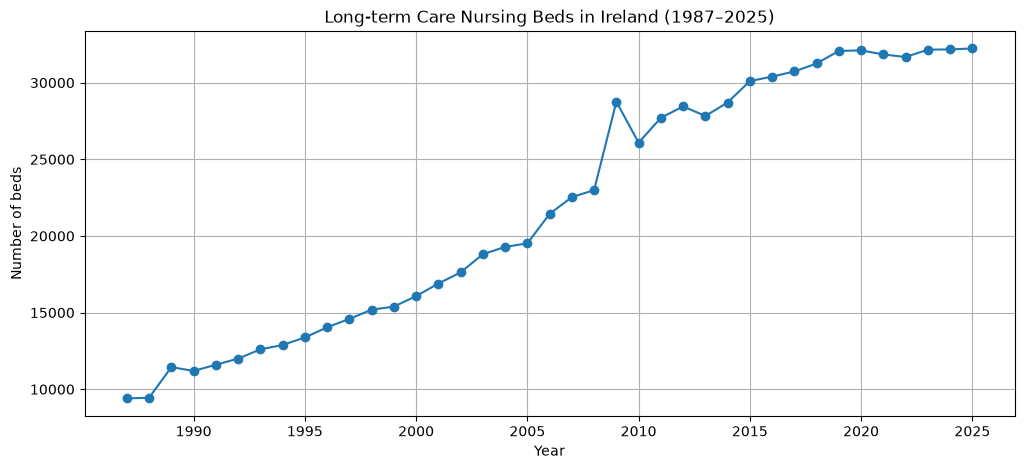

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    df_nursing_beds['YEAR'],
    df_nursing_beds['VALUE'],
    marker='o'
)

plt.title('Long-term Care Nursing Beds in Ireland (1987–2025)')
plt.xlabel('Year')
plt.ylabel('Number of beds')
plt.grid(True)
plt.show()

In [10]:
df_nursing_beds.columns

Index(['STATISTIC', 'Statistic Label', 'YEAR', 'Year', 'BEDTYPE', 'Bed type',
       'UNIT', 'VALUE', 'FLAG', 'Flag'],
      dtype='str')

In [11]:
df_nursing_beds.columns = (
    df_nursing_beds.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

df_nursing_beds.columns

Index(['statistic', 'statistic_label', 'year', 'year', 'bedtype', 'bed_type',
       'unit', 'value', 'flag', 'flag'],
      dtype='str')

In [12]:
df_nursing_beds.columns = [
    'statistic',
    'statistic_label',
    'year_code',
    'year',
    'bedtype',
    'bed_type',
    'unit',
    'value',
    'flag_code',
    'flag_description'
]

df_nursing_beds.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   statistic         39 non-null     str  
 1   statistic_label   39 non-null     str  
 2   year_code         39 non-null     int64
 3   year              39 non-null     int64
 4   bedtype           39 non-null     str  
 5   bed_type          39 non-null     str  
 6   unit              39 non-null     str  
 7   value             39 non-null     int64
 8   flag_code         3 non-null      str  
 9   flag_description  3 non-null      str  
dtypes: int64(3), str(7)
memory usage: 3.2 KB


In [13]:
df_nursing_beds.head()

,statistic,statistic_label,year_code,year,bedtype,bed_type,unit,value,flag_code,flag_description
0,LTCBEDS,Beds in residential long-term care facilities,1987,1987,NURSING,Long-term care nursing bed,Number,9400,NaN,NaN
1,LTCBEDS,Beds in residential long-term care facilities,1988,1988,NURSING,Long-term care nursing bed,Number,9450,NaN,NaN
2,LTCBEDS,Beds in residential long-term care facilities,1989,1989,NURSING,Long-term care nursing bed,Number,11443,NaN,NaN
3,LTCBEDS,Beds in residential long-term care facilities,1990,1990,NURSING,Long-term care nursing bed,Number,11195,NaN,NaN
4,LTCBEDS,Beds in residential long-term care facilities,1991,1991,NURSING,Long-term care nursing bed,Number,11600,NaN,NaN


In [14]:
columns_to_check = [
    'statistic',
    'statistic_label',
    'year_code',
    'bedtype',
    'bed_type',
    'unit'
]

for column in columns_to_check:
    print(f'{column}: {df_nursing_beds[column].nunique()} unique values')

statistic: 1 unique values
statistic_label: 1 unique values
year_code: 39 unique values
bedtype: 1 unique values
bed_type: 1 unique values
unit: 1 unique values


In [15]:
print((df_nursing_beds['year_code'] == df_nursing_beds['year']).all())

True


In [16]:
df_nursing_beds_clean = df_nursing_beds[
    ['year', 'value', 'flag_code', 'flag_description']
].copy()

In [17]:
df_nursing_beds_clean.head()

,year,value,flag_code,flag_description
0,1987,9400,NaN,NaN
1,1988,9450,NaN,NaN
2,1989,11443,NaN,NaN
3,1990,11195,NaN,NaN
4,1991,11600,NaN,NaN


In [18]:
df_nursing_beds_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 39 entries, 0 to 38
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   year              39 non-null     int64
 1   value             39 non-null     int64
 2   flag_code         3 non-null      str  
 3   flag_description  3 non-null      str  
dtypes: int64(2), str(2)
memory usage: 1.3 KB


In [19]:
df_nursing_beds_clean.duplicated().sum()

np.int64(0)

In [20]:
df_nursing_beds_clean['year'].duplicated().sum()

np.int64(0)

In [21]:
df_nursing_beds_clean.isna().sum()

year                 0
value                0
flag_code           36
flag_description    36
dtype: int64

In [22]:
print((df_nursing_beds_clean.isna().mean() * 100).round(2))

year                 0.00
value                0.00
flag_code           92.31
flag_description    92.31
dtype: float64


In [23]:
print('First year: ', df_nursing_beds_clean['year'].min())
print('Last year: ', df_nursing_beds_clean['year'].max())

print('Minimum beds: ', df_nursing_beds_clean['value'].min())
print('Maximum beds: ', df_nursing_beds_clean['value'].max())

First year:  1987
Last year:  2025
Minimum beds:  9400
Maximum beds:  32233


In [24]:
print((df_nursing_beds_clean['value'] > 0).all())

True


### Data Cleaning and Validation

The original dataset contained 39 annual records and 10 columns. During the cleaning process, column names were standardized using snake_case.

Redundant columns were removed because they contained constant information or duplicated the year variable. The final dataset contains four columns: `year`, `value`, `flag_code` and `flag_description`.

The validation confirmed that:

- There are no duplicated rows or years.
- The `year` and `value` columns have no missing values.
- Missing values in the flag columns were preserved because they indicate years without a recorded observation flag.
- The dataset covers the period from 1987 to 2025.
- All bed counts are positive.

Three observations (2009, 2010 and 2014) contain the flag `B` (*Break in series*). These records were retained, but their values will be interpreted with caution when analysing historical trends.

The cleaned dataset is stored in `df_beds_clean`.

## Exploratory Data Analysis

### Nursing Home Bed Capacity (2020–2025)

This section explores the evolution of long-term care nursing bed capacity in Ireland between 2020 and 2025.

The goal is to understand how the number of available nursing home beds changed during this period and compare this trend with the growth of the older population.

In [25]:
df_beds_recent = df_nursing_beds_clean[
    df_nursing_beds_clean['year'].between(2020, 2025)
].copy()

In [26]:
df_beds_recent

,year,value,flag_code,flag_description
33,2020,32104,NaN,NaN
34,2021,31842,NaN,NaN
35,2022,31674,NaN,NaN
36,2023,32155,NaN,NaN
37,2024,32169,NaN,NaN
38,2025,32233,NaN,NaN


In [27]:
initial_beds = df_beds_recent.loc[
    df_beds_recent['year'] == 2020, 'value'
].iloc[0]

final_beds = df_beds_recent.loc[
    df_beds_recent['year'] == 2025, 'value'
].iloc[0]

absolute_change = final_beds - initial_beds

percentage_change = (absolute_change / initial_beds) * 100

print(f'Initial beds (2020): {initial_beds:,}')
print(f'Final beds (2025): {final_beds:,}')
print(f'Absolute change: {absolute_change:,}')
print(f'Percentage change: {percentage_change:.2f}%')

Initial beds (2020): 32,104
Final beds (2025): 32,233
Absolute change: 129
Percentage change: 0.40%


In [28]:
df_beds_recent = df_beds_recent.sort_values('year').copy()

df_beds_recent['absolute_change'] = (
    df_beds_recent['value'].diff()
)

df_beds_recent['percentage_change'] = (
    df_beds_recent['value'].pct_change() * 100
)

df_beds_recent

,year,value,flag_code,flag_description,absolute_change,percentage_change
33,2020,32104,NaN,NaN,NaN,NaN
34,2021,31842,NaN,NaN,-262.0,-0.816098
35,2022,31674,NaN,NaN,-168.0,-0.527605
36,2023,32155,NaN,NaN,481.0,1.518596
37,2024,32169,NaN,NaN,14.0,0.043539
38,2025,32233,NaN,NaN,64.0,0.198949


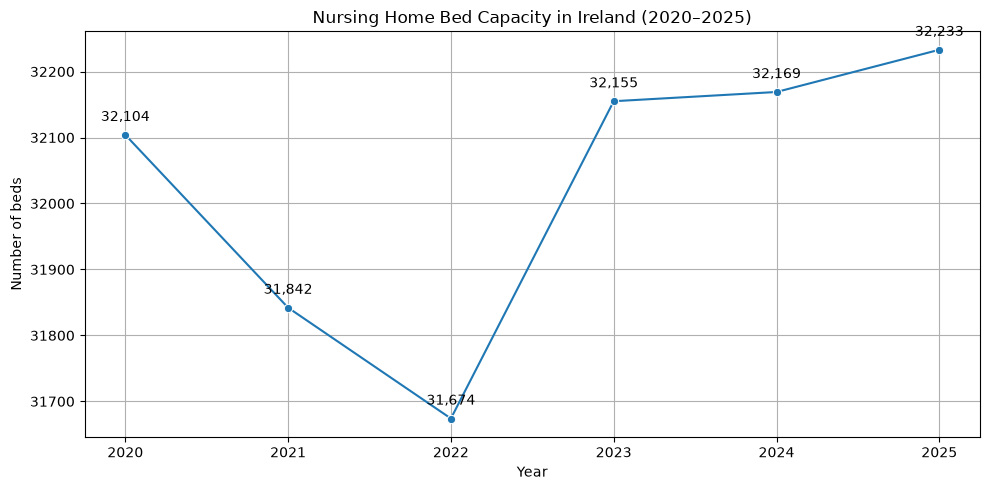

In [30]:
plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=df_beds_recent,
    x='year',
    y='value',
    marker='o'
)

for _, row in df_beds_recent.iterrows():
    ax.annotate(
        f"{row['value']:,}",
        (row['year'], row['value']),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center'
    )

plt.title('Nursing Home Bed Capacity in Ireland (2020–2025)')
plt.xlabel('Year')
plt.ylabel('Number of beds')
plt.xticks(df_beds_recent['year'])
plt.grid(True)
plt.tight_layout()
plt.show()

We can see three distinct phases here:

- 2020–2022: a steady drop in capacity, falling from 32,104 to 31,674 beds.

- 2022–2023: a strong rebound, with an increase of 481 beds.

- 2023–2025: slower growth, reaching 32,233 beds.

One quick note: the Y-axis starts around 31,650 instead of zero. While this makes smaller shifts easier to spot, it can also make the changes look more dramatic visually—something worth keeping in mind when looking at overall capacity.

### Did nursing home bed capacity grow at the same pace as the population aged 65 and over between 2020 and 2025?

In [31]:
df_population = pd.read_csv('../data/processed/population_65_plus.csv')

df_population.head()

,year,older_population
0,2020,726.1
1,2021,747.4
2,2022,781.4
3,2023,806.3
4,2024,833.3


In [32]:
print(df_population.dtypes)
print(df_beds_recent.dtypes)

year                  int64
older_population    float64
dtype: object
year                   int64
value                  int64
flag_code                str
flag_description         str
absolute_change      float64
percentage_change    float64
dtype: object


In [33]:
df_capacity_analysis = pd.merge(
    df_beds_recent,
    df_population,
    on='year',
    how='inner'
)

df_capacity_analysis

,year,value,flag_code,flag_description,absolute_change,percentage_change,older_population
0,2020,32104,NaN,NaN,NaN,NaN,726.1
1,2021,31842,NaN,NaN,-262.0,-0.816098,747.4
2,2022,31674,NaN,NaN,-168.0,-0.527605,781.4
3,2023,32155,NaN,NaN,481.0,1.518596,806.3
4,2024,32169,NaN,NaN,14.0,0.043539,833.3
5,2025,32233,NaN,NaN,64.0,0.198949,861.2


In [34]:
df_capacity_analysis['beds_per_1000_older_people'] = (
    df_capacity_analysis['value'] / 
    df_capacity_analysis['older_population']
)

df_capacity_analysis[
    ['year', 'value', 'older_population', 'beds_per_1000_older_people']
]

,year,value,older_population,beds_per_1000_older_people
0,2020,32104,726.1,44.214296
1,2021,31842,747.4,42.603693
2,2022,31674,781.4,40.534937
3,2023,32155,806.3,39.879697
4,2024,32169,833.3,38.604344
5,2025,32233,861.2,37.428007


In [35]:
initial_ratio = df_capacity_analysis.loc[
    df_capacity_analysis['year'] == 2020,
    'beds_per_1000_older_people'
].iloc[0]

final_ratio = df_capacity_analysis.loc[
    df_capacity_analysis['year'] == 2025,
    'beds_per_1000_older_people'
].iloc[0]

ratio_change = final_ratio - initial_ratio

ratio_percentage_change = (
    ratio_change / initial_ratio
) * 100

print(f'Absolute change: {ratio_change:.2f}')
print(f'Percentage change: {ratio_percentage_change:.2f}%')

Absolute change: -6.79
Percentage change: -15.35%


In [36]:
df_capacity_analysis['population_index'] = (
    df_capacity_analysis['older_population'] / 
    df_capacity_analysis.loc[
        df_capacity_analysis['year'] == 2020,
        'older_population'
    ].iloc[0]
) * 100

df_capacity_analysis['beds_index'] = (
    df_capacity_analysis['value'] /
    df_capacity_analysis.loc[
        df_capacity_analysis['year'] == 2020,
        'value'
    ].iloc[0]
) * 100

df_capacity_analysis[
    ['year', 'population_index', 'beds_index']
]

,year,population_index,beds_index
0,2020,100.000000,100.000000
1,2021,102.933480,99.183902
2,2022,107.616031,98.660603
3,2023,111.045311,100.158859
4,2024,114.763807,100.202467
5,2025,118.606253,100.401819


In [37]:
df_index = df_capacity_analysis[
    ['year', 'population_index', 'beds_index']
].melt(
    id_vars='year',
    var_name='indicator',
    value_name='index_value'
)

df_index

,year,indicator,index_value
0,2020,population_index,100.000000
1,2021,population_index,102.933480
2,2022,population_index,107.616031
3,2023,population_index,111.045311
4,2024,population_index,114.763807
5,2025,population_index,118.606253
6,2020,beds_index,100.000000
7,2021,beds_index,99.183902
8,2022,beds_index,98.660603
9,2023,beds_index,100.158859


In [40]:
df_index['indicator'] = (
    df_index['indicator'].replace({
        'population_index': 'Population',
        'beds_index': 'Beds'
    })
)

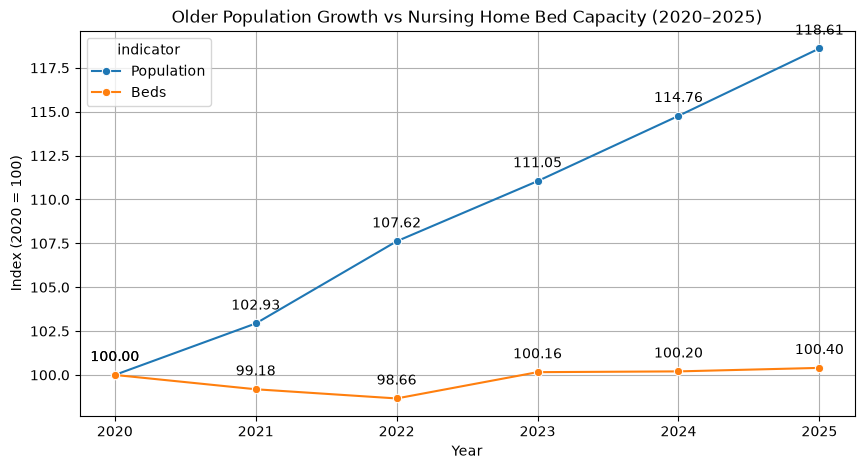

In [46]:
plt.figure(figsize=(10, 5))

ax = sns.lineplot(
    data=df_index,
    x='year',
    y='index_value',
    hue='indicator',
    marker='o'
)

for _, row in df_index.iterrows():
    ax.annotate(
        f"{row['index_value']:,.2f}",
        (row['year'], row['index_value']),
        textcoords='offset points',
        xytext=(0, 10),
        ha='center'
    )

plt.title('Older Population Growth vs Nursing Home Bed Capacity (2020–2025)')
plt.xlabel('Year')
plt.ylabel('Index (2020 = 100)')
plt.xticks(df_index['year'].unique())
plt.grid(True)

plt.show()

### Population Growth vs Nursing Home Bed Capacity (2020–2025)

The comparison shows a clear difference between the growth of Ireland's older population and the number of reported nursing home beds.

Between 2020 and 2025:

- The population aged 65 and over increased by **18.61%**.
- The number of reported nursing home beds increased by only **0.40%**.
- Beds per 1,000 people aged 65+ decreased from **44.21 to 37.43**, a reduction of **15.35%**.

These findings suggest that nursing home bed capacity has not grown at the same pace as the older population.

However, this comparison does not establish whether there is a shortage of nursing home beds. Population aged 65+ is not equivalent to the population requiring residential care, and the number of reported beds does not necessarily represent occupied or immediately available beds.

Further analysis of occupancy, waiting lists and care needs would be necessary to assess actual capacity pressure.